# Research Question 3
How many reviews are needed to trust a former-vs-current rating gap?

# 0. Setup

In [123]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

seed = 507

# 1. Data Preparation

In [124]:
processed_path = '../data/processed/processed.parquet'

df = pd.read_parquet(processed_path)

In [125]:
df.columns

Index(['firm_id', 'rating', 'former', 'emp_type', 'tenure', 'year', 'date',
       'number of reviews', 'cons', 'job'],
      dtype='str')

In [126]:
# Create sample
# Firms must have reviews from at least 1,000 current and at least 1,000 former employees

sample_df = df.groupby("firm_id").filter(
    lambda g: (g["former"] == 1).sum() >= 1000 and (g["former"] == 0).sum() >= 1000
)

In [127]:
# Calculate normal approximation with all reviews and with the reference firms

sd_all = df["rating"].std()
n_star_all = int(np.ceil(2 * (1.96 * sd_all / 0.25) ** 2))

sd_ref = sample_df["rating"].std()
n_star_ref = int(np.ceil(2 * (1.96 * sd_ref / 0.25) ** 2))

group_counts = sample_df.groupby(["firm_id", "former"]).size().unstack(fill_value=0)
enough = group_counts.min(axis=1) >= n_star_ref

print(f"All reviews SD: {sd_all:.2f}, n* per group: {n_star_all}")
print(f"Reference firms SD: {sd_ref:.2f}, n* per group: {n_star_ref}")

All reviews SD: 1.22, n* per group: 183
Reference firms SD: 1.18, n* per group: 171


# 2. Experiment

In [128]:
# Define functions

def calculate_reference_gap(df):
    s = df.groupby("former")["rating"].mean()
    return s.loc[1] - s.loc[0]

def calculate_sample_gap(f, c, n, rng):
    f_mean = rng.choice(f, size=n, replace=True).mean()
    c_mean = rng.choice(c, size=n, replace=True).mean()
    return f_mean - c_mean

def build_gap_table(df, n, n_iter=1000, tolerances=(0.25,), seed=0):
    rng = np.random.default_rng(seed)
    rows = []
    for firm_id, g in df.groupby("firm_id"):
        ref = calculate_reference_gap(g)
        f = g.loc[g["former"] == 1, "rating"].to_numpy()
        c = g.loc[g["former"] == 0, "rating"].to_numpy()
        for i in n:
            gaps = np.array([calculate_sample_gap(f, c, i, rng) for _ in range(n_iter)])
            errors = np.abs(gaps - ref)
            for tolerance in tolerances:
                rows.append({
                    "firm_id": firm_id,
                    "n": i,
                    "tolerance": tolerance,
                    "n_former": len(f),
                    "n_current": len(c),
                    "proportion": (errors <= tolerance).mean()
                })
    return pd.DataFrame(rows)

def find_n_star(result, tolerance, level):
    coverage = result[result["tolerance"] == tolerance].groupby("n")["proportion"].mean()
    return coverage[coverage > level].index.min()

def normal_n_star(sd, tolerance, z):
    return int(np.ceil(2 * (z * sd / tolerance) ** 2))

In [129]:
result = build_gap_table(sample_df, range(50, 301, 10), seed=seed)

# Result

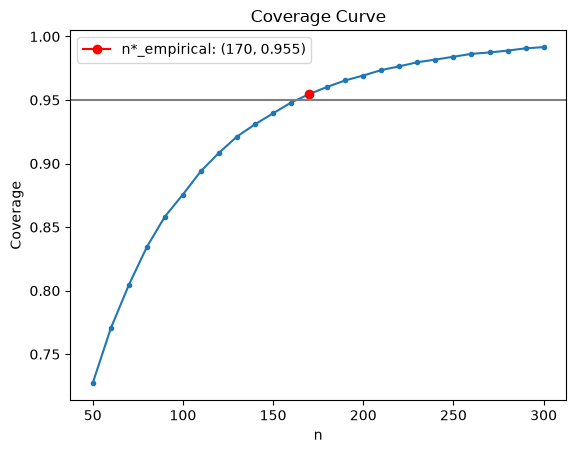

In [130]:
# Calculate overall coverage per n
n_overall = result.groupby("n")["proportion"].mean()
n_star_empirical = next(n for n, p in n_overall.items() if p > 0.95)


plt.plot(n_overall, marker="o", markersize=3)
plt.plot(n_star_empirical, n_overall.loc[n_star_empirical], marker="o", color="red", label=f"n*_empirical: ({n_star_empirical}, {n_overall.loc[n_star_empirical]:.3f})")
plt.axhline(y=0.95, color="gray")
plt.title("Coverage Curve")
plt.xlabel("n")
plt.ylabel("Coverage")

plt.legend()
plt.show()

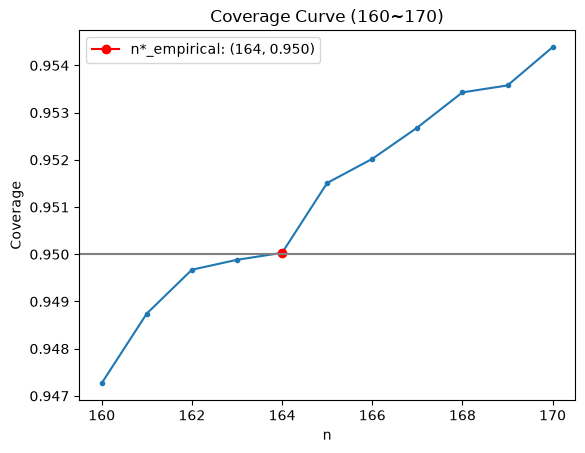

In [131]:
result_2 = build_gap_table(sample_df, range(160, 171), seed=seed)

n_overall_2 = result_2.groupby("n")["proportion"].mean()
n_star_empirical_2 = next(n for n, p in n_overall_2.items() if p > 0.95)


plt.plot(n_overall_2, marker="o", markersize=3)
plt.plot(n_star_empirical_2, n_overall_2.loc[n_star_empirical_2], marker="o", color="red", label=f"n*_empirical: ({n_star_empirical_2}, {n_overall_2.loc[n_star_empirical_2]:.3f})")
plt.axhline(y=0.95, color="gray")
plt.title("Coverage Curve (160~170)")
plt.xlabel("n")
plt.ylabel("Coverage")

plt.legend()
plt.show()


In [133]:
# Compute how many companies have n*_empirical or more reviews

counts = df.groupby("firm_id")["former"].agg(n_former="sum", n_total="size")
counts["n_current"] = counts["n_total"] - counts["n_former"]
counts["n"] = counts[["n_former", "n_current"]].min(axis=1)

print(f"{len(counts[counts["n"] >= n_star_empirical_2]) / len(counts) * 100:.3f}% of employers have at least n*_empirical (164) reviews from both former and current employees\n")

# Examine how different the ratios from 160 reviews to 170 reviews
print(f"{len(counts[counts["n"] >= 160]) / len(counts) * 100:.3f}% of employers have at least 160 reviews from both former and current employees")
print(f"{len(counts[counts["n"] >= 170]) / len(counts) * 100:.3f}% of employers have at least 170 reviews from both former and current employees")

7.173% of employers have at least n*_empirical (164) reviews from both former and current employees

7.274% of employers have at least 160 reviews from both former and current employees
7.007% of employers have at least 170 reviews from both former and current employees


# Sensitivity Analysis

In [137]:
sensitivity = build_gap_table(sample_df, range(50, 301, 10), tolerances=(0.20, 0.25, 0.30), seed=seed)

In [138]:
conditions = [(0.20, 0.95), (0.25, 0.95), (0.30, 0.95), (0.25, 0.90)]
z = {0.95: 1.96, 0.90: 1.645}

rows = []
for tolerance, level in conditions:
    n_star = find_n_star(sensitivity, tolerance, level)
    rows.append({
        "tolerance": tolerance,
        "level": level,
        "n_star_empirical": n_star,
        "n_star_all": normal_n_star(sd_all, tolerance, z[level]),
        "n_star_ref": normal_n_star(sd_ref, tolerance, z[level]),
        "employers_pct": (counts["n"] >= n_star).mean() * 100 if pd.notna(n_star) else np.nan,
    })
pd.DataFrame(rows)

,tolerance,level,n_star_empirical,n_star_all,n_star_ref,employers_pct
0,0.20,0.95,260,286,267,5.092325
1,0.25,0.95,170,183,171,7.007357
2,0.30,0.95,120,127,119,8.980092
3,0.25,0.90,120,129,121,8.980092


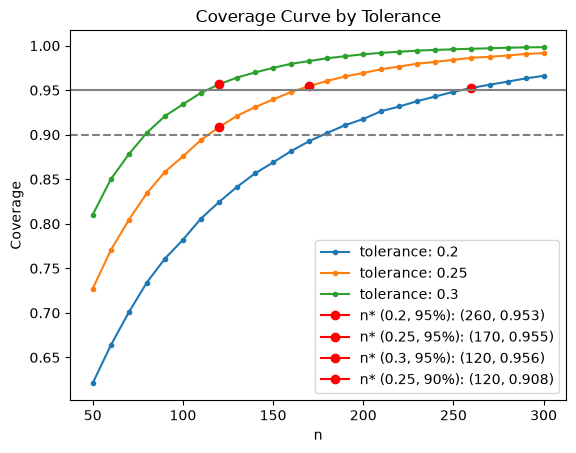

In [140]:
coverage = sensitivity.groupby(["tolerance", "n"])["proportion"].mean().unstack("tolerance")

for tolerance in coverage.columns:
    plt.plot(coverage[tolerance], marker="o", markersize=3, label=f"tolerance: {tolerance}")

for tolerance, level in conditions:
    n_star = find_n_star(sensitivity, tolerance, level)
    plt.plot(n_star, coverage.loc[n_star, tolerance], marker="o", color="red", label=f"n* ({tolerance}, {level:.0%}): ({n_star}, {coverage.loc[n_star, tolerance]:.3f})")

plt.axhline(y=0.95, color="gray")
plt.axhline(y=0.90, color="gray", linestyle="--")
plt.title("Coverage Curve by Tolerance")
plt.xlabel("n")
plt.ylabel("Coverage")

plt.legend()
plt.show()